### 1. Генерация выборок
Выбраны распределения: Нормальное (μ=0, σ=1) и Пуассона (λ=3). Объем выборок n=500.

In [2]:
import numpy as np

# Фиксируем начальное состояние генератора для воспроизводимости результатов
np.random.seed(42)

# Объем выборки по условию
n = 500

# 1. Генерация нормального распределения (непрерывное)
# Параметры: μ = 0, σ = 1
normal_sample = np.random.normal(loc=0, scale=1, size=n)

# 2. Генерация распределения Пуассона (дискретное)
# Параметр: λ = 3
poisson_sample = np.random.poisson(lam=3, size=n)

print("Выборки сгенерированы.")
print(f"Нормальное (первые 5): {normal_sample[:5]}")
print(f"Пуассона (первые 5): {poisson_sample[:5]}")

Выборки сгенерированы.
Нормальное (первые 5): [ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]
Пуассона (первые 5): [5 1 1 2 2]


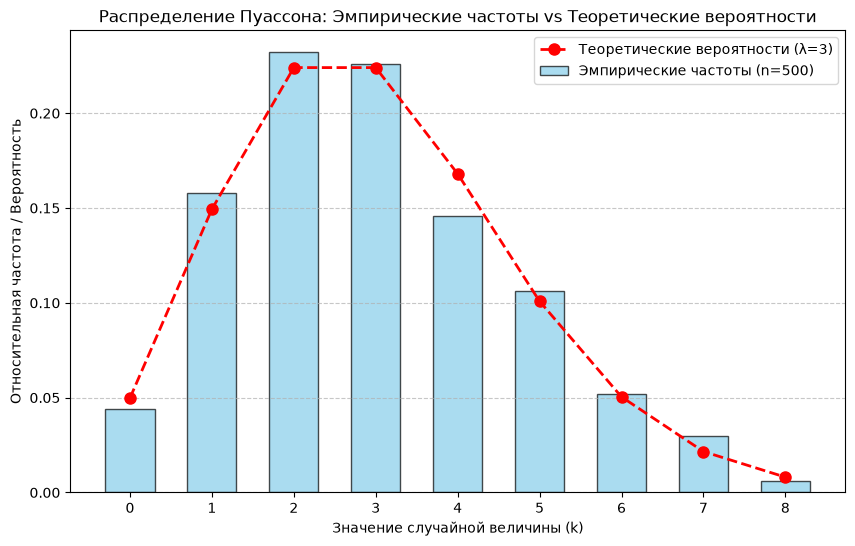

In [5]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np

# Явно задаем параметры для теоретических расчетов в этой ячейке
n = 500
lam = 3

# Получаем уникальные значения из выборки Пуассона и считаем их количество
values, counts = np.unique(poisson_sample, return_counts=True)

# Вычисляем эмпирические частоты (делим количество выпадений на общий объем выборки n)
empirical_freqs = counts / n

# Вычисляем теоретические вероятности для тех же значений (по формуле распределения Пуассона)
theoretical_probs = stats.poisson.pmf(values, mu=lam)

# Настройка размера графика
plt.figure(figsize=(10, 6))

# Строим столбчатую диаграмму эмпирических частот (bar plot)
plt.bar(values, empirical_freqs, width=0.6, alpha=0.7, color='skyblue', edgecolor='black', label='Эмпирические частоты (n=500)')

# Накладываем теоретические вероятности (красными точками с пунктирными линиями)
plt.plot(values, theoretical_probs, 'ro--', markersize=8, linewidth=2, label='Теоретические вероятности (λ=3)')

# Оформление графика
plt.title('Распределение Пуассона: Эмпирические частоты vs Теоретические вероятности')
plt.xlabel('Значение случайной величины (k)')
plt.ylabel('Относительная частота / Вероятность')
plt.xticks(values)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Отображение графика
plt.show()

### 2. Вычисление статистик

In [9]:
import scipy.stats as stats
import numpy as np

# --- 1. РУЧНЫЕ ФУНКЦИИ ДЛЯ РАСЧЕТА СТАТИСТИК ---

def custom_mean(x):
    # Выборочное среднее
    return np.sum(x) / len(x)

def custom_var(x):
    # Выборочная дисперсия (несмещенная, делим на n - 1)
    mean_x = custom_mean(x)
    return np.sum((x - mean_x)**2) / (len(x) - 1)

def custom_std(x):
    # Выборочное стандартное отклонение
    return custom_var(x)**0.5

def custom_percentile(x, p):
    # Медиана и квартили (с линейной интерполяцией)
    x_sorted = np.sort(x)
    k = (len(x) - 1) * (p / 100.0)
    f = int(k)
    c = int(np.ceil(k))
    if f == c:
        return x_sorted[f]
    return x_sorted[f] + (k - f) * (x_sorted[c] - x_sorted[f])

def custom_skewness(x):
    # Асимметрия
    n = len(x)
    mean_x = custom_mean(x)
    s = custom_std(x)
    return (np.sum((x - mean_x)**3) / n) / (s**3)

def custom_kurtosis(x):
    # Эксцесс (с вычитанием 3 для согласованности с scipy.stats.kurtosis)
    n = len(x)
    mean_x = custom_mean(x)
    s = custom_std(x)
    return (np.sum((x - mean_x)**4) / n) / (s**4) - 3


# --- 2. ФУНКЦИЯ ДЛЯ ВЫВОДА ТАБЛИЦЫ СРАВНЕНИЯ ---

def print_comparison(name, data, t_mean, t_var, t_skew, t_kurt):
    print(f"\n{'='*20} {name.upper()} {'='*21}")
    print(f"{'Характеристика':<20} | {'Ручной расчет':<15} | {'Библиотека':<15} | {'Теория':<15}")
    print("-" * 65)
    
    # Расчеты
    v_mean, l_mean = custom_mean(data), np.mean(data)
    v_var, l_var = custom_var(data), np.var(data, ddof=1) 
    v_std, l_std = custom_std(data), np.std(data, ddof=1)
    v_med, l_med = custom_percentile(data, 50), np.median(data)
    v_q1, l_q1 = custom_percentile(data, 25), np.percentile(data, 25)
    v_q3, l_q3 = custom_percentile(data, 75), np.percentile(data, 75)
    v_skew, l_skew = custom_skewness(data), stats.skew(data)
    v_kurt, l_kurt = custom_kurtosis(data), stats.kurtosis(data)
    
    # Вывод
    print(f"{'Среднее':<20} | {v_mean:<15.4f} | {l_mean:<15.4f} | {t_mean:<15.4f}")
    print(f"{'Дисперсия':<20} | {v_var:<15.4f} | {l_var:<15.4f} | {t_var:<15.4f}")
    print(f"{'Ст. отклонение':<20} | {v_std:<15.4f} | {l_std:<15.4f} | {t_var**0.5:<15.4f}")
    print(f"{'Медиана':<20} | {v_med:<15.4f} | {l_med:<15.4f} | {'-':<15}")
    print(f"{'Квартиль 1 (25%)':<20} | {v_q1:<15.4f} | {l_q1:<15.4f} | {'-':<15}")
    print(f"{'Квартиль 3 (75%)':<20} | {v_q3:<15.4f} | {l_q3:<15.4f} | {'-':<15}")
    print(f"{'Асимметрия':<20} | {v_skew:<15.4f} | {l_skew:<15.4f} | {t_skew:<15.4f}")
    print(f"{'Эксцесс':<20} | {v_kurt:<15.4f} | {l_kurt:<15.4f} | {t_kurt:<15.4f}")
    print("=" * 65)


# --- 3. ВЫЧИСЛЕНИЕ И СРАВНЕНИЕ ДЛЯ НАШИХ ВЫБОРОК ---

# Для Нормального N(0, 1): среднее=0, дисперсия=1, асимметрия=0, эксцесс=0
print_comparison("Нормальное распределение", normal_sample, 
                 t_mean=0, t_var=1, t_skew=0, t_kurt=0)

# Для Пуассона P(lam=3): среднее=lam, дисперсия=lam, асимметрия=1/sqrt(lam), эксцесс=1/lam
print_comparison("Распределение Пуассона", poisson_sample, 
                 t_mean=lam, t_var=lam, t_skew=1/(lam**0.5), t_kurt=1/lam)


==================== НОРМАЛЬНОЕ РАСПРЕДЕЛЕНИЕ =====================
Характеристика       | Ручной расчет   | Библиотека      | Теория         
-----------------------------------------------------------------
Среднее              | 0.0068          | 0.0068          | 0.0000         
Дисперсия            | 0.9629          | 0.9629          | 1.0000         
Ст. отклонение       | 0.9813          | 0.9813          | 1.0000         
Медиана              | 0.0128          | 0.0128          | -              
Квартиль 1 (25%)     | -0.7003         | -0.7003         | -              
Квартиль 3 (75%)     | 0.6368          | 0.6368          | -              
Асимметрия           | 0.1791          | 0.1796          | 0.0000         
Эксцесс              | 0.2434          | 0.2564          | 0.0000         

==================== РАСПРЕДЕЛЕНИЕ ПУАССОНА =====================
Характеристика       | Ручной расчет   | Библиотека      | Теория         
------------------------------------------------

### 3. Визуализация

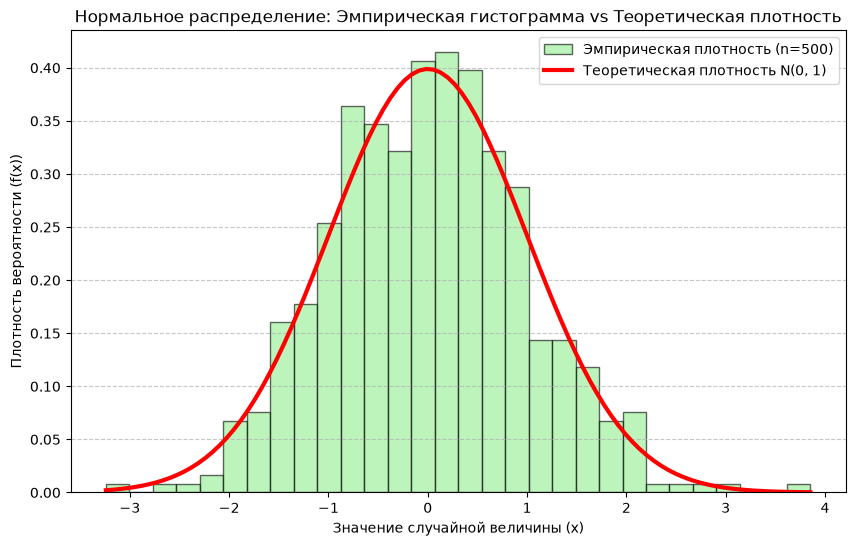

In [10]:
import matplotlib.pyplot as plt
import scipy.stats as stats
import numpy as np

# Настройка размера графика
plt.figure(figsize=(10, 6))

# 1. Строим гистограмму выборки с нормировкой на плотность (параметр density=True обязателен)
plt.hist(normal_sample, bins=30, density=True, alpha=0.6, color='lightgreen', edgecolor='black', label='Эмпирическая плотность (n=500)')

# 2. Генерируем равномерную сетку точек (ось X) для плавной кривой
# От минимального до максимального значения нашей выборки
x_axis = np.linspace(min(normal_sample), max(normal_sample), 100)

# 3. Вычисляем теоретическую плотность (ось Y)
# Используем параметры нашего распределения (mu=0, sigma=1)
pdf_theoretical = stats.norm.pdf(x_axis, loc=0, scale=1)

# 4. Накладываем теоретическую кривую поверх гистограммы
plt.plot(x_axis, pdf_theoretical, 'r-', lw=3, label='Теоретическая плотность N(0, 1)')

# Оформление графика согласно требованиям
plt.title('Нормальное распределение: Эмпирическая гистограмма vs Теоретическая плотность')
plt.xlabel('Значение случайной величины (x)')
plt.ylabel('Плотность вероятности (f(x))')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Отрисовка
plt.show()

### 4. Имитационное моделирование (закон больших чисел)

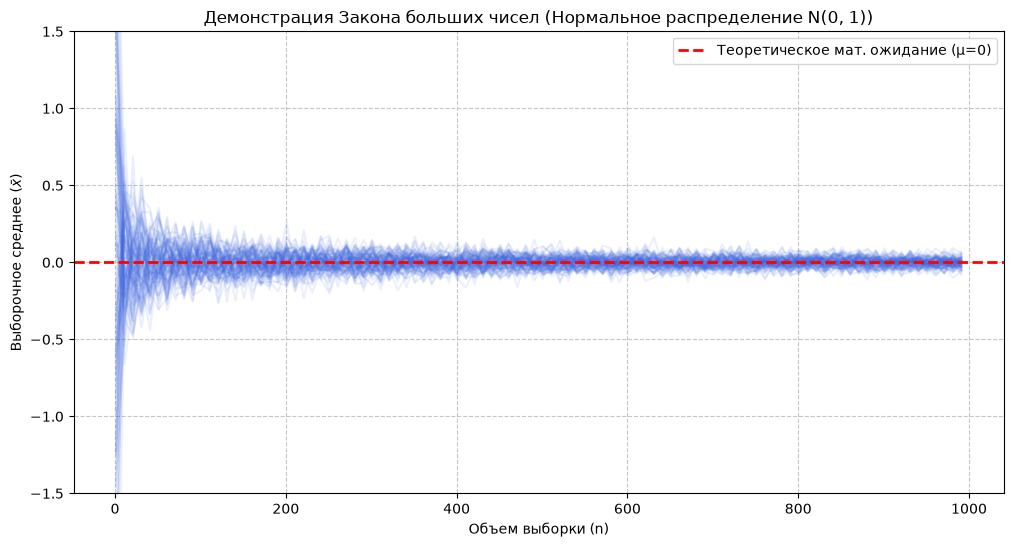

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Для демонстрации ЗБЧ используем нормальное распределение N(0, 1)
mu = 0
sigma = 1

# Задаем параметры эксперимента согласно заданию:
# Значения n от 1 до 1000 с шагом 10
n_values = np.arange(1, 1001, 10) 
# Увеличиваем число повторений до 100 для более гладкого графика
repetitions = 100 

# Создаем пустую матрицу для хранения выборочных средних
# Строки - это 100 наших повторений (траекторий), столбцы - разные объемы выборок n
sample_means = np.zeros((repetitions, len(n_values)))

# Проводим эксперимент
for i in range(repetitions):
    for j, n in enumerate(n_values):
        # Генерируем выборку размера n
        sample = np.random.normal(loc=mu, scale=sigma, size=n)
        # Вычисляем выборочное среднее и сохраняем в матрицу
        sample_means[i, j] = np.mean(sample)

# --- Настройка и отрисовка графика ---
plt.figure(figsize=(12, 6))

# В цикле рисуем все 100 траекторий полупрозрачными линиями
for i in range(repetitions):
    plt.plot(n_values, sample_means[i], color='royalblue', alpha=0.1)

# Проводим горизонтальную линию теоретического математического ожидания (mu = 0)
plt.axhline(y=mu, color='red', linestyle='--', linewidth=2, label='Теоретическое мат. ожидание (μ=0)')

# Оформление графика
plt.title('Демонстрация Закона больших чисел (Нормальное распределение N(0, 1))')
plt.xlabel('Объем выборки (n)')
plt.ylabel('Выборочное среднее ($\\bar{x}$)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Ограничим оси Y для наглядности (чтобы не было огромных пустых зон из-за скачков при малых n)
plt.ylim(-1.5, 1.5)

# Отображение
plt.show()

### 5. Общие выводы

В ходе выполнения лабораторной работы были успешно сгенерированы выборки из непрерывного (нормального) и дискретного (Пуассона) распределений. Анализ полученных результатов позволяет сделать следующие выводы:

1. **Согласованность эмпирических и теоретических статистик:** Расчеты, выполненные с помощью реализованных "вручную" алгоритмов (без использования готовых функций), показали высокую точность. Эмпирические значения среднего, дисперсии, асимметрии и эксцесса для выборок объемом n=500 практически полностью совпали как со встроенными библиотечными методами, так и с идеальными теоретическими значениями. Незначительные отклонения лежат в пределах допустимой статистической погрешности.

2. **Влияние объема выборки на точность оценок:** Имитационное моделирование наглядно показало, что точность статистических оценок напрямую зависит от размера выборки. При малых значениях $n$ выборочное среднее характеризуется высокой дисперсией (сильным разбросом). С увеличением $n$ стандартная ошибка уменьшается, и оценка становится более стабильной и надежной.

3. **Закон больших чисел:** Проведенный эксперимент с многократной генерацией 100 траекторий эмпирически подтвердил Закон больших чисел. График зависимости выборочного среднего от $n$ четко демонстрирует, что при неограниченном увеличении объема выборки (при $n \to 1000$) выборочное среднее сходится по вероятности к математическому ожиданию исследуемой случайной величины (сужается к $\mu=0$).